<a href="https://colab.research.google.com/github/kondraschovAV1999/net-fingerprinting/blob/master/Fingerprinting_Network_Document_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import urllib.request
import os

# Set download target and headers to prevent HTTP 403
url = 'https://data.mendeley.com/public-files/datasets/zsffy3j9y6/files/b061b2f5-d92b-44ae-9f6d-e05a6cc55363/file_downloaded'
download_path = 'downloaded_file.rar'

req = urllib.request.Request(
    url,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'}
)

try:
    print("Downloading file from Mendeley using custom headers...")
    with urllib.request.urlopen(req) as response, open(download_path, 'wb') as out_file:
        out_file.write(response.read())
    print("Download completed! Checking file details:")

    # Show file size
    file_size = os.path.getsize(download_path)
    print(f"File size: {file_size / (1024*1024):.2f} MB")

    # Install rarfile/unrar and extract
    print("Installing rarfile package...")
    !pip install -q rarfile

    # Make sure system unrar is installed (needed by rarfile)
    !apt-get install -y unrar

    import rarfile
    print("Extracting RAR archive...")
    with rarfile.RarFile(download_path) as rf:
        rf.extractall(path='extracted_pcaps')
    print("Extraction complete. Extracted files:")
    print(os.listdir('extracted_pcaps'))

except Exception as e:
    print(f"Error during download/extraction: {e}")
    print("Attempting raw system command extraction as backup...")
    !mkdir -p extracted_pcaps && unrar x -y downloaded_file.rar extracted_pcaps/
    if os.path.exists('extracted_pcaps'):
        print("Files in extracted directory:")
        print(os.listdir('extracted_pcaps'))

In [ ]:
import glob
import os

# Define the extraction directory path
pcap_dir = 'extracted_pcaps'

# Search for all .pcap files in the directory
pcap_files = glob.glob(os.path.join(pcap_dir, '*.pcap'))

print(f"Found {len(pcap_files)} PCAP files:")
for i, file_path in enumerate(pcap_files, 1):
    file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"{i}. {os.path.basename(file_path)} ({file_size_mb:.2f} MB)")

Found 3 PCAP files:
1. 1723117813_Duolingo_22.66-12.56.pcap (34.63 MB)
2. 1723117813_Google Drive_22.66-12.56.pcap (10.67 MB)
3. 1723117813_LinkedIn_22.66-12.56.pcap (100.38 MB)


In [ ]:
# Install scapy for parsing and viewing PCAP files
!pip install -q scapy

from scapy.all import rdpcap
import os

# Select the first PCAP file from our list
target_pcap = 'extracted_pcaps/1723117813_Duolingo_22.66-12.56.pcap'

print(f"Loading {target_pcap}...")
packets = rdpcap(target_pcap)

print(f"\nSuccessfully loaded {len(packets)} packets.")
print("\n--- Summary of the first 15 packets ---")
for idx, packet in enumerate(packets[:15]):
    print(f"Packet {idx + 1}: {packet.summary()}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 16.4 MB/s eta 0:00:00
Loading extracted_pcaps/1723117813_Duolingo_22.66-12.56.pcap...

Successfully loaded 39175 packets.

--- Summary of the first 15 packets ---
Packet 1: Ether / IP / TCP 192.168.137.42:56332 > 3.160.212.116:https S
Packet 2: Ether / IP / TCP 192.168.137.42:48256 > 34.234.114.119:https S
Packet 3: Ether / IP / TCP 192.168.137.42:54986 > 18.66.196.26:https S
Packet 4: Ether / IP / TCP 3.160.212.116:https > 192.168.137.42:56332 SA
Packet 5: Ether / IP / TCP 18.66.196.26:https > 192.168.137.42:54986 SA
Packet 6: Ether / IP / TCP 34.234.114.119:https > 192.168.137.42:48256 SA
Packet 7: Ether / IP / TCP 192.168.137.42:54986 > 18.66.196.26:https A
Packet 8: Ether / IP / TCP 192.168.137.42:56332 > 3.160.212.116:https A
Packet 9: Ether / IP / TCP 192.168.137.42:48256 > 34.234.114.119:https A
Packet 10: Ether / IP / TCP 192.168.137.42:56332 > 3.160.212.116:https FA
Packet 11: Ether / IP / TCP 192.168.137.42:48256 > 34.234

In [ ]:
import os
from collections import defaultdict
from scapy.all import rdpcap, IP, TCP, UDP, DNS, Raw

def analyze_pcap(pcap_path):
    print(f"=== Analyzing: {os.path.basename(pcap_path)} ===")
    try:
        packets = rdpcap(pcap_path)
    except Exception as e:
        print(f"Failed to load {pcap_path}: {e}")
        return

    suspicious_events = []
    connection_attempts = defaultdict(set)
    dns_queries = []

    for idx, pkt in enumerate(packets):
        # Check if packet contains IP layer
        if pkt.haslayer(IP):
            ip_src = pkt[IP].src
            ip_dst = pkt[IP].dst

            # 1. Look for potential port scanning (one host contacting many different ports on another host)
            if pkt.haslayer(TCP):
                dport = pkt[TCP].dport
                connection_attempts[(ip_src, ip_dst)].add(dport)

                # Look for cleartext HTTP traffic
                if dport == 80 and pkt.haslayer(Raw):
                    payload = pkt[Raw].load.decode('utf-8', errors='ignore')
                    if any(kw in payload.lower() for kw in ["user", "pass", "login", "secret"]):
                        suspicious_events.append({
                            "packet_index": idx + 1,
                            "type": "Cleartext Credentials Alert",
                            "description": f"Potential login credentials sent in plaintext from {ip_src} to {ip_dst}"
                        })

            # 2. Collect DNS queries for inspection
            if pkt.haslayer(DNS) and pkt[DNS].qd:
                dns_query = pkt[DNS].qd.qname.decode('utf-8', errors='ignore')
                dns_queries.append((ip_src, dns_query))

    # Evaluate Port Scanning thresholds
    for (src, dst), ports in connection_attempts.items():
        if len(ports) > 25:
            suspicious_events.append({
                "packet_index": "Multiple",
                "type": "Potential Port Scan",
                "description": f"Host {src} targeted {len(ports)} different ports on {dst}"
            })

    # Display Results
    if not suspicious_events:
        print("No highly suspicious activities detected based on basic thresholds.\n")
    else:
        print(f"Detected {len(suspicious_events)} suspicious events:")
        for event in suspicious_events:
            print(f"[!] Type: {event['type']} (Packet Ref: {event['packet_index']})")
            print(f"    Description: {event['description']}\n")

# Analyze the first loaded PCAP file as a demonstration
analyze_pcap('extracted_pcaps/1723117813_Duolingo_22.66-12.56.pcap')

In [ ]:
# Analyze all extracted PCAP files
for pcap_file in pcap_files:
    analyze_pcap(pcap_file)

=== Analyzing: 1723117813_Duolingo_22.66-12.56.pcap ===
No highly suspicious activities detected based on basic thresholds.

=== Analyzing: 1723117813_Google Drive_22.66-12.56.pcap ===
Detected 1 suspicious events:
[!] Type: Potential Port Scan (Packet Ref: Multiple)
    Description: Host 142.251.209.1 targeted 53 different ports on 192.168.137.166

=== Analyzing: 1723117813_LinkedIn_22.66-12.56.pcap ===
No highly suspicious activities detected based on basic thresholds.



In [ ]:
# Install scapy if not already present in the current runtime environment
!pip install -q scapy

import os
import glob
import pandas as pd
from scapy.all import rdpcap, IP, TCP, UDP

def pcap_to_dataframe(pcap_path):
    print(f"Processing: {os.path.basename(pcap_path)}...")
    try:
        packets = rdpcap(pcap_path)
    except Exception as e:
        print(f"Failed to read {pcap_path}: {e}")
        return pd.DataFrame()

    packet_data = []
    for idx, pkt in enumerate(packets):
        # Base structural data
        row = {
            'file_source': os.path.basename(pcap_path),
            'packet_num': idx + 1,
            'time': float(pkt.time),
            'len': len(pkt),
            'protocol': 'Other',
            'src_ip': None,
            'dst_ip': None,
            'src_port': None,
            'dst_port': None
        }

        if pkt.haslayer(IP):
            row['src_ip'] = pkt[IP].src
            row['dst_ip'] = pkt[IP].dst

            if pkt.haslayer(TCP):
                row['protocol'] = 'TCP'
                row['src_port'] = pkt[TCP].sport
                row['dst_port'] = pkt[TCP].dport
            elif pkt.haslayer(UDP):
                row['protocol'] = 'UDP'
                row['src_port'] = pkt[UDP].sport
                row['dst_port'] = pkt[UDP].dport
            else:
                row['protocol'] = 'IP'

        packet_data.append(row)

    return pd.DataFrame(packet_data)

# Define directory and dynamically search for PCAP files
pcap_dir = 'extracted_pcaps'
pcap_files = glob.glob(os.path.join(pcap_dir, '*.pcap'))

print(f"Found {len(pcap_files)} PCAP files to process in '{pcap_dir}'")

# Convert all and merge into a single dataframe
all_dfs = []
for file in pcap_files:
    df_temp = pcap_to_dataframe(file)
    if not df_temp.empty:
        all_dfs.append(df_temp)

if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    output_csv = 'all_packets_data.csv'
    combined_df.to_csv(output_csv, index=False)
    print(f"\nSuccess! Combined packet data saved to {output_csv}")
    print(f"Total Packets Processed: {len(combined_df)}")

    # Display first few rows
    display(combined_df.head())
else:
    print("No packets could be processed. Please make sure PCAP files exist in 'extracted_pcaps' folder.")

Found 0 PCAP files to process in 'extracted_pcaps'
No packets could be processed. Please make sure PCAP files exist in 'extracted_pcaps' folder.


Reading packet lengths from PCAP files...
Reading lengths from 1723117813_Duolingo_22.66-12.56.pcap...
Reading lengths from 1723117813_Google Drive_22.66-12.56.pcap...
Reading lengths from 1723117813_LinkedIn_22.66-12.56.pcap...


/tmp/ipykernel_1589/242166370.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_lengths, x='Application', y='Length', palette='Set2')


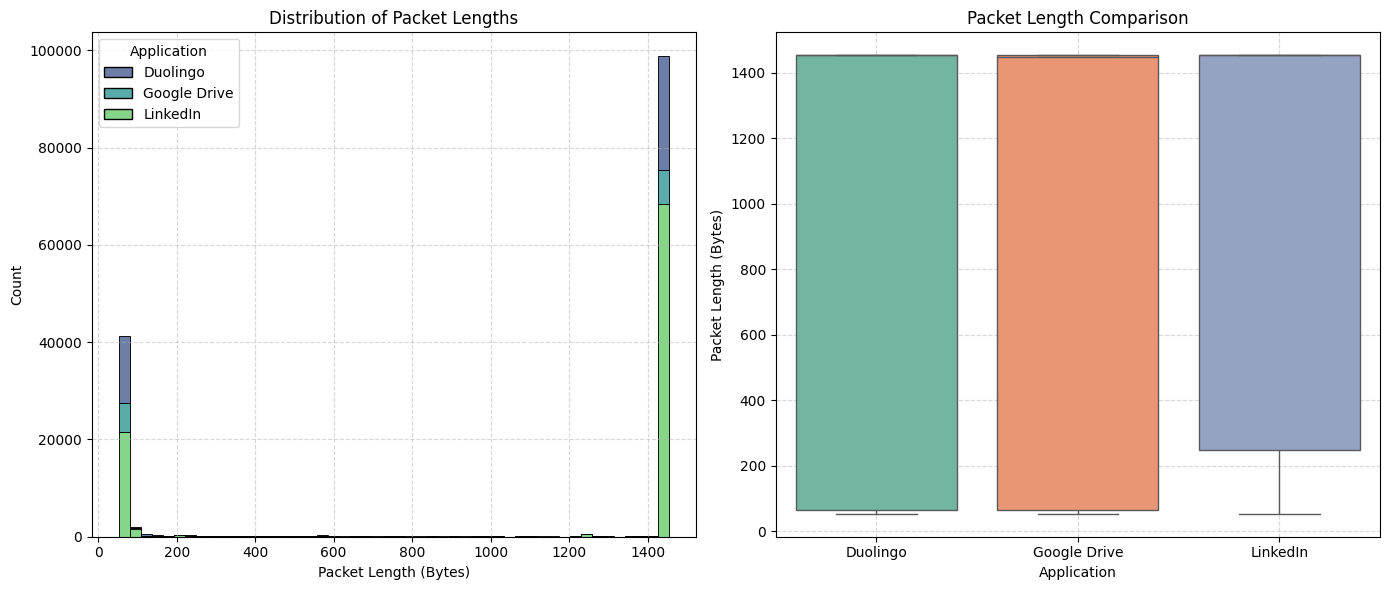

In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scapy.all import rdpcap

# Ensure we have parsed the PCAPs into a DataFrame
pcap_dir = 'extracted_pcaps'
pcap_files = glob.glob(os.path.join(pcap_dir, '*.pcap'))

all_packet_lengths = []

print("Reading packet lengths from PCAP files...")
for file in pcap_files:
    print(f"Reading lengths from {os.path.basename(file)}...")
    try:
        # Fast read of packet lengths using a generator
        packets = rdpcap(file)
        lengths = [len(pkt) for pkt in packets]
        file_name = os.path.basename(file).split('_')[1] # Get app name like Duolingo, Google Drive, etc.
        df_temp = pd.DataFrame({'Length': lengths, 'Application': file_name})
        all_packet_lengths.append(df_temp)
    except Exception as e:
        print(f"Error reading {file}: {e}")

if all_packet_lengths:
    df_lengths = pd.concat(all_packet_lengths, ignore_index=True)

    # Set up the plotting environment
    plt.figure(figsize=(14, 6))

    # Subplot 1: Distribution of Packet Lengths (Histogram)
    plt.subplot(1, 2, 1)
    sns.histplot(data=df_lengths, x='Length', hue='Application', multiple='stack', bins=50, palette='viridis')
    plt.title('Distribution of Packet Lengths')
    plt.xlabel('Packet Length (Bytes)')
    plt.ylabel('Count')
    plt.grid(True, linestyle='--', alpha=0.5)

    # Subplot 2: Boxplot of Packet Lengths by Application
    plt.subplot(1, 2, 2)
    sns.boxplot(data=df_lengths, x='Application', y='Length', palette='Set2')
    plt.title('Packet Length Comparison')
    plt.xlabel('Application')
    plt.ylabel('Packet Length (Bytes)')
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()
else:
    print("No packet length data available to plot.")

In [ ]:
# First, install the necessary package
!pip install -q rarfile

import urllib.request
import os
import rarfile

# Re-download and extract if the directory is empty
pcap_dir = 'extracted_pcaps'
url = 'https://data.mendeley.com/public-files/datasets/zsffy3j9y6/files/b061b2f5-d92b-44ae-9f6d-e05a6cc55363/file_downloaded'
download_path = 'downloaded_file.rar'

if not os.path.exists(pcap_dir) or len(os.listdir(pcap_dir)) == 0:
    print("Re-downloading the dataset to restore the PCAP files...")
    req = urllib.request.Request(
        url,
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    )
    try:
        with urllib.request.urlopen(req) as response, open(download_path, 'wb') as out_file:
            out_file.write(response.read())

        !apt-get install -y unrar

        print("Extracting RAR file...")
        with rarfile.RarFile(download_path) as rf:
            rf.extractall(path=pcap_dir)
        print("Successfully restored files:", os.listdir(pcap_dir))
    except Exception as e:
        print(f"Error during recovery: {e}")
else:
    print("PCAP files are already present in 'extracted_pcaps'.")

Re-downloading the dataset to restore the PCAP files...
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Extracting RAR file...
Successfully restored files: ['1723117813_Duolingo_22.66-12.56.pcap', '1723117813_Google Drive_22.66-12.56.pcap', '1723117813_LinkedIn_22.66-12.56.pcap']


In [1]:
import os
import glob
import pandas as pd
from scapy.all import PcapReader, IP, TCP, UDP

# Define directory and search for PCAP files
pcap_dir = 'extracted_pcaps'
pcap_files = glob.glob(os.path.join(pcap_dir, '*.pcap'))

def pcap_to_dataframe(pcap_path, max_packets=100000):
    print(f"Processing: {os.path.basename(pcap_path)}...")
    packet_data = []

    try:
        # Using PcapReader to stream packets iteratively to save memory and time
        with PcapReader(pcap_path) as reader:
            for idx, pkt in enumerate(reader):
                if idx >= max_packets:
                    print(f"  Reached maximum packet limit ({max_packets}) for this file.")
                    break

                # Base structural data
                row = {
                    'file_source': os.path.basename(pcap_path),
                    'packet_num': idx + 1,
                    'time': float(pkt.time),
                    'len': len(pkt),
                    'protocol': 'Other',
                    'src_ip': None,
                    'dst_ip': None,
                    'src_port': None,
                    'dst_port': None
                }

                if pkt.haslayer(IP):
                    row['src_ip'] = pkt[IP].src
                    row['dst_ip'] = pkt[IP].dst

                    if pkt.haslayer(TCP):
                        row['protocol'] = 'TCP'
                        row['src_port'] = pkt[TCP].sport
                        row['dst_port'] = pkt[TCP].dport
                    elif pkt.haslayer(UDP):
                        row['protocol'] = 'UDP'
                        row['src_port'] = pkt[UDP].sport
                        row['dst_port'] = pkt[UDP].dport
                    else:
                        row['protocol'] = 'IP'

                packet_data.append(row)
    except Exception as e:
        print(f"  Failed to read {pcap_path}: {e}")
        return pd.DataFrame()

    return pd.DataFrame(packet_data)

# Convert all discovered PCAP files and combine them
all_dfs = []
for file in pcap_files:
    df_temp = pcap_to_dataframe(file)
    if not df_temp.empty:
        all_dfs.append(df_temp)

if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    output_csv = 'all_packets_data.csv'
    combined_df.to_csv(output_csv, index=False)
    print(f"\nSuccess! Combined packet data saved to: {output_csv}")
    print(f"Total Packets Processed: {len(combined_df)}")
    display(combined_df.head())
else:
    print("No PCAP files found or processed.")

KeyboardInterrupt: 

In [ ]:
# Group the combined packet data by protocol and summarize counts
if 'combined_df' in globals():
    protocol_summary = combined_df.groupby('protocol').size().reset_index(name='packet_count')
    protocol_summary['percentage'] = (protocol_summary['packet_count'] / protocol_summary['packet_count'].sum()) * 100
    protocol_summary = protocol_summary.sort_values(by='packet_count', ascending=False).reset_index(drop=True)
    display(protocol_summary)
else:
    print("Error: combined_df is not available in the workspace. Please make sure the extraction and parsing cells are run.")

,protocol,packet_count,percentage
0,TCP,147941,99.859601
1,UDP,208,0.140399


In [ ]:
# =====================================================================
# PLACEHOLDER: INSERT THE LINK TO BE DECIPHERED HERE
# Replace the empty string below with your target encrypted or source URL
# =====================================================================
DECIPHER_LINK = "https://data.mendeley.com/public-api/zip/96jwzrp7fd/download/1"

import os
import glob

# Define the extraction directory containing your files
pcap_dir = 'extracted_pcaps'

print("--- Full List of Extracted Workspace Files ---")
if os.path.exists(pcap_dir):
    files = glob.glob(os.path.join(pcap_dir, '*'))
    for idx, file_path in enumerate(sorted(files), 1):
        file_name = os.path.basename(file_path)
        file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{idx:02d}. [PCAP File] {file_name} ({file_size_mb:.2f} MB)")
else:
    print(f"Directory '{pcap_dir}' not found. Please extract the files first.")

if os.path.exists('all_packets_data.csv'):
    csv_size_mb = os.path.getsize('all_packets_data.csv') / (1024 * 1024)
    print(f"\n[Dataset Output] all_packets_data.csv ({csv_size_mb:.2f} MB)")

# Process the new link if provided
if DECIPHER_LINK:
    print(f"\nProcessing target link: {DECIPHER_LINK}")
    # Add your specific decryption/download logic here
else:
    print("\nReady for a new link. Insert it in the DECIPHER_LINK variable above to begin processing.")

--- Full List of Extracted Workspace Files ---
01. [PCAP File] 1723117813_Duolingo_22.66-12.56.pcap (34.63 MB)
02. [PCAP File] 1723117813_Google Drive_22.66-12.56.pcap (10.67 MB)
03. [PCAP File] 1723117813_LinkedIn_22.66-12.56.pcap (100.38 MB)

[Dataset Output] all_packets_data.csv (15.53 MB)

Processing target link: https://data.mendeley.com/public-api/zip/96jwzrp7fd/download/1


Click below to download your combined dataset:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

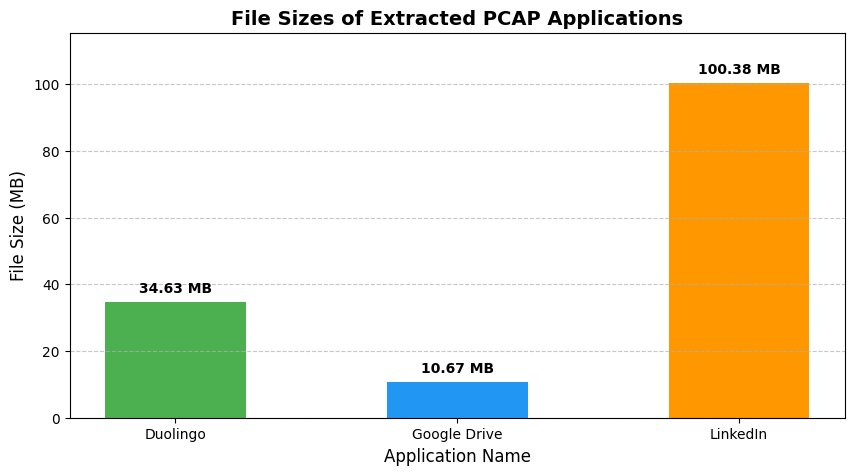

In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Create a download button/link for the CSV file
if os.path.exists('all_packets_data.csv'):
    print("Click below to download your combined dataset:")
    files.download('all_packets_data.csv')
else:
    print("Error: all_packets_data.csv not found!")

# 2. Gather file sizes of the extracted PCAP files
pcap_dir = 'extracted_pcaps'
pcap_files = glob.glob(os.path.join(pcap_dir, '*.pcap'))

file_details = []
for file_path in pcap_files:
    name = os.path.basename(file_path).split('_')[1]  # Extracting app name like Duolingo, Google Drive, etc.
    size_mb = os.path.getsize(file_path) / (1024 * 1024)
    file_details.append({'Application': name, 'Size (MB)': size_mb})

df_details = pd.DataFrame(file_details)

# 3. Create a bar chart showing file details
if not df_details.empty:
    plt.figure(figsize=(10, 5))
    colors = ['#4CAF50', '#2196F3', '#FF9800']
    bars = plt.bar(df_details['Application'], df_details['Size (MB)'], color=colors[:len(df_details)], width=0.5)

    # Add values on top of the bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.2f} MB", ha='center', va='bottom', fontweight='bold')

    plt.title('File Sizes of Extracted PCAP Applications', fontsize=14, fontweight='bold')
    plt.xlabel('Application Name', fontsize=12)
    plt.ylabel('File Size (MB)', fontsize=12)
    plt.ylim(0, max(df_details['Size (MB)']) * 1.15)  # Add some headroom for label space
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print("No extracted PCAP files found to visualize.")

## App Fingerprinting with a 1D CNN

Classify which application (Duolingo, Google Drive, LinkedIn) generated each network flow using a 1D CNN over per-flow packet sequences, and evaluate predictions with accuracy, precision, recall, and F1-score.

### Evaluation Metrics

`evaluate_metrics(y_true, y_pred, class_names)` takes the true and predicted labels and returns:
* `accuracy`
* `precision_macro`, `recall_macro`, `f1_macro`: unweighted mean across classes (each app counts equally, important given the class imbalance)
* `precision_weighted`, `recall_weighted`, `f1_weighted`: mean weighted by class support
* `per_class`: per-application precision / recall / F1 / support table
* `confusion_matrix`: rows = true app, columns = predicted app

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

def evaluate_metrics(y_true, y_pred, class_names=None):
    """Compute accuracy, precision, recall and F1 from true vs. predicted labels.

    y_true, y_pred: label arrays of equal length. Pass them by keyword -- swapping
                    them silently swaps precision and recall.
    class_names:    optional list where class_names[i] names integer class i. If given,
                    every class is reported even if it is absent from y_true/y_pred.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if class_names is None:
        labels = np.unique(np.concatenate([y_true, y_pred]))
        class_names = [str(label) for label in labels]
    else:
        labels = np.arange(len(class_names))

    metrics = {'accuracy': accuracy_score(y_true, y_pred)}

    # Macro = each class counts equally; weighted = classes weighted by support
    for avg in ('macro', 'weighted'):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=labels, average=avg, zero_division=0
        )
        metrics[f'precision_{avg}'] = precision
        metrics[f'recall_{avg}'] = recall
        metrics[f'f1_{avg}'] = f1

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    metrics['per_class'] = pd.DataFrame(
        {'precision': precision, 'recall': recall, 'f1': f1, 'support': support},
        index=class_names
    )
    metrics['confusion_matrix'] = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=labels),
        index=[f'true_{name}' for name in class_names],
        columns=[f'pred_{name}' for name in class_names]
    )
    return metrics

# Sanity check on a toy example with hand-computed values
toy = evaluate_metrics(y_true=[0, 0, 1, 1, 2, 2], y_pred=[0, 1, 1, 1, 2, 0], class_names=['A', 'B', 'C'])

assert np.isclose(toy['accuracy'], 4 / 6)                         # 0.667
assert np.isclose(toy['precision_macro'], (1/2 + 2/3 + 1) / 3)    # 0.722
assert np.isclose(toy['recall_macro'], (1/2 + 1 + 1/2) / 3)       # 0.667
assert np.isclose(toy['f1_macro'], (1/2 + 4/5 + 2/3) / 3)         # 0.656

print("Sanity check passed. Scalar metrics:")
for name, value in toy.items():
    if np.isscalar(value):
        print(f"  {name:<20} {value:.3f}")
display(toy['per_class'])
display(toy['confusion_matrix'])

In [ ]:
# Stopgap until the dev/data_download pipeline merges: download every Iraq capture session that contains
# one of our target apps, so each app has enough pcaps for the chronological per-pcap split.
# Session -> apps mapping comes from Table A3 of the dataset's DetailedDescription (doi:10.17632/23v73hh7r5.1).
!pip install -q rarfile
!apt-get install -y -qq unrar

import glob
import json
import os
import shutil
import urllib.request
import pandas as pd
import rarfile

DATASET_ID = 'zsffy3j9y6'  # ITC-NetMingledApp, Iraq-Baghdad scenario
TARGET_APPS = ['Duolingo', 'Google Drive', 'LinkedIn']
SESSIONS = {  # session -> target apps it contains (7 Duolingo, 12 Google Drive, 7 LinkedIn pcaps; ~1.8 GB)
    'Iraq-03': ['LinkedIn'],
    'Iraq-09': ['Google Drive'],
    'Iraq-10': ['Google Drive'],
    'Iraq-12': ['Duolingo', 'Google Drive'],
    'Iraq-14': ['LinkedIn'],
    'Iraq-17': ['Duolingo', 'Google Drive'],
    'Iraq-30': ['LinkedIn'],
    'Iraq-31': ['Google Drive'],
    'Iraq-32': ['LinkedIn'],
    'Iraq-33': ['Google Drive'],
    'Iraq-35': ['Google Drive'],
    'Iraq-36': ['Duolingo', 'Google Drive', 'LinkedIn'],
    'Iraq-37': ['Duolingo'],
    'Iraq-39': ['Duolingo', 'Google Drive'],
    'Iraq-40': ['Google Drive'],
    'Iraq-41': ['Google Drive', 'LinkedIn'],
    'Iraq-42': ['Duolingo', 'Google Drive', 'LinkedIn'],
    'Iraq-46': ['Duolingo'],
}
SESSIONS_DIR = 'iraq_sessions'
HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'}

assert 'pcap_to_dataframe' in globals(), "Run the PcapReader parsing cell above first (it defines pcap_to_dataframe)"

# Look up each archive's download URL from the Mendeley public API
api_url = f'https://data.mendeley.com/public-api/datasets/{DATASET_ID}/files?folder_id=root&version=1'
with urllib.request.urlopen(urllib.request.Request(api_url, headers=HEADERS), timeout=60) as response:
    listing = json.load(response)
listing = listing if isinstance(listing, list) else listing.get('files', [])
download_urls = {
    os.path.splitext(f['filename'])[0]: (f.get('content_details') or {}).get('download_url') or f.get('download_url')
    for f in listing
}

for session in SESSIONS:
    session_dir = os.path.join(SESSIONS_DIR, session)
    if glob.glob(os.path.join(session_dir, '**', '*.pcap'), recursive=True):
        print(f"{session}: already extracted, skipping")
        continue
    if not download_urls.get(session):
        print(f"{session}: no download URL in the dataset listing, skipping")
        continue
    archive_path = os.path.join(SESSIONS_DIR, f'{session}.rar')
    os.makedirs(SESSIONS_DIR, exist_ok=True)
    print(f"{session}: downloading and extracting...")
    with urllib.request.urlopen(urllib.request.Request(download_urls[session], headers=HEADERS), timeout=300) as response, \
            open(archive_path, 'wb') as out_file:
        shutil.copyfileobj(response, out_file)
    with rarfile.RarFile(archive_path) as rf:
        rf.extractall(path=session_dir)
    os.remove(archive_path)  # free disk space; the extracted pcaps are all we need

def pcap_app(path):
    """App name from a '{timestamp}_{App}_{speeds}.pcap' filename, or None if it doesn't match."""
    parts = os.path.basename(path).split('_')
    return parts[1] if len(parts) > 2 else None

# Each session also holds other apps' pcaps; parse only the target apps (replaces the single-session combined_df)
target_pcaps = sorted(p for p in glob.glob(os.path.join(SESSIONS_DIR, '**', '*.pcap'), recursive=True)
                      if pcap_app(p) in TARGET_APPS)
combined_df = pd.concat([pcap_to_dataframe(p) for p in target_pcaps], ignore_index=True)
combined_df.to_csv('all_packets_data.csv', index=False)

print(f"\nParsed {len(target_pcaps)} target-app pcaps ({len(combined_df):,} packets); saved to all_packets_data.csv")
display(pd.Series([pcap_app(p) for p in target_pcaps]).value_counts().rename_axis('app').to_frame('pcaps'))

In [ ]:
# Build per-flow packet sequences for the 1D CNN and split them into train/val/test sets
import numpy as np
import pandas as pd

# Reload the parsed packets if the runtime restarted after the parsing cell
if 'combined_df' not in globals():
    combined_df = pd.read_csv('all_packets_data.csv')

SEQ_LEN = 32     # packets per flow fed to the CNN (longer flows truncated, shorter zero-padded)
MIN_PKTS = 4     # drop tiny flows (e.g. bare TCP handshakes) that carry little app signal
MAX_LEN = 1514   # full Ethernet frame size, used to scale packet lengths into [-1, 1]

pkt_df = combined_df[combined_df['protocol'].isin(['TCP', 'UDP'])].dropna(
    subset=['src_ip', 'dst_ip', 'src_port', 'dst_port']
).copy()
pkt_df['app'] = pkt_df['file_source'].str.split('_').str[1]
pkt_df['src_port'] = pkt_df['src_port'].astype(int)
pkt_df['dst_port'] = pkt_df['dst_port'].astype(int)

# The capture device is the IP seen in the most packets of each capture (it differs between captures)
endpoints = pd.concat([
    pkt_df[['file_source', 'src_ip']].rename(columns={'src_ip': 'ip'}),
    pkt_df[['file_source', 'dst_ip']].rename(columns={'dst_ip': 'ip'})
])
device_ip = endpoints.groupby('file_source')['ip'].agg(lambda ips: ips.mode().iloc[0])
pkt_df['device_ip'] = pkt_df['file_source'].map(device_ip)

# Keep only traffic to/from the capture device; direction +1 = sent by device, -1 = received
pkt_df = pkt_df[(pkt_df['src_ip'] == pkt_df['device_ip']) | (pkt_df['dst_ip'] == pkt_df['device_ip'])].copy()
outbound = pkt_df['src_ip'] == pkt_df['device_ip']
pkt_df['direction'] = np.where(outbound, 1, -1)

# Bidirectional flow id: both directions of a connection share one (device endpoint, remote endpoint) key
src_ep = pkt_df['src_ip'] + ':' + pkt_df['src_port'].astype(str)
dst_ep = pkt_df['dst_ip'] + ':' + pkt_df['dst_port'].astype(str)
pkt_df['flow_id'] = (pkt_df['file_source'] + '|' + pkt_df['protocol'] + '|'
                     + src_ep.where(outbound, dst_ep) + '|' + dst_ep.where(outbound, src_ep))

pkt_df = pkt_df.sort_values(['flow_id', 'time'])
pkt_df['iat_ms'] = pkt_df.groupby('flow_id')['time'].diff().fillna(0.0) * 1000
pkt_df['pos'] = pkt_df.groupby('flow_id').cumcount()

flow_sizes = pkt_df.groupby('flow_id').size()
flow_ids = flow_sizes[flow_sizes >= MIN_PKTS].index
seq = pkt_df[pkt_df['flow_id'].isin(flow_ids) & (pkt_df['pos'] < SEQ_LEN)]

# X: (n_flows, 2 channels, SEQ_LEN) -- channel 0 = signed packet length, channel 1 = log inter-arrival time
X = np.zeros((len(flow_ids), 2, SEQ_LEN), dtype=np.float32)
rows = flow_ids.get_indexer(seq['flow_id'])
cols = seq['pos'].to_numpy()
X[rows, 0, cols] = seq['direction'].to_numpy() * np.clip(seq['len'].to_numpy() / MAX_LEN, 0, 1)  # clip guards against >MTU offloaded frames
X[rows, 1, cols] = np.log1p(seq['iat_ms'].to_numpy())

# y: one app label per flow, encoded as integers 0..n_classes-1 (source pcap kept for the split)
flow_info = pkt_df.groupby('flow_id')[['app', 'file_source']].first().loc[flow_ids]
flow_app = flow_info['app']
y, class_names = pd.factorize(flow_app, sort=True)
class_names = list(class_names)

print("Capture device IP per file:")
for file_source, ip in device_ip.items():
    print(f"  {file_source}: {ip}")

kept_sizes = flow_sizes.loc[flow_ids]
print(f"\nKept {len(flow_ids)} of {len(flow_sizes)} flows (>= {MIN_PKTS} packets)")
display(pd.DataFrame({
    'flows': kept_sizes.groupby(flow_app).size(),
    'median_pkts_per_flow': kept_sizes.groupby(flow_app).median(),
    f'pct_flows_>={SEQ_LEN}_pkts': (kept_sizes >= SEQ_LEN).groupby(flow_app).mean().mul(100).round(1)
}))

# Team split: for each app, sort its pcaps by capture timestamp (filename prefix) and assign the
# oldest 70% to train, the next 15% to val and the newest 15% to test. All flows from a pcap stay
# in the same set, and every set contains every app.
VAL_FRAC, TEST_FRAC = 0.15, 0.15

pcaps = pd.DataFrame({'file_source': pkt_df['file_source'].unique()})
pcaps['app'] = pcaps['file_source'].str.split('_').str[1]
pcaps['timestamp'] = pcaps['file_source'].str.split('_').str[0].astype(int)
pcaps = pcaps.sort_values(['app', 'timestamp']).reset_index(drop=True)

pcaps_per_app = pcaps.groupby('app').size()
print(f"\nPcaps per app: {pcaps_per_app.to_dict()}")
too_few = pcaps_per_app[pcaps_per_app < 3]
if not too_few.empty:
    raise ValueError(
        f"The pcap-level split needs at least 3 pcaps per app (one each for train/val/test), "
        f"but these apps have fewer: {too_few.to_dict()}. Load more capture sessions first."
    )

# Val and test each get at least one pcap per app; train gets the rest
rank = pcaps.groupby('app').cumcount()  # 0 = oldest pcap of that app
n_pcaps = pcaps['app'].map(pcaps_per_app)
n_val = (n_pcaps * VAL_FRAC).round().clip(lower=1)
n_test = (n_pcaps * TEST_FRAC).round().clip(lower=1)
pcaps['split'] = np.select([rank < n_pcaps - n_val - n_test, rank < n_pcaps - n_test], ['train', 'val'], default='test')
display(pcaps)

flow_split = flow_info['file_source'].map(pcaps.set_index('file_source')['split']).to_numpy()
X_train, y_train = X[flow_split == 'train'], y[flow_split == 'train']
X_val, y_val = X[flow_split == 'val'], y[flow_split == 'val']
X_test, y_test = X[flow_split == 'test'], y[flow_split == 'test']

print(f"\nX: {X.shape}, y: {y.shape}")
display(pd.DataFrame(
    {split: np.bincount(labels, minlength=len(class_names))
     for split, labels in [('train', y_train), ('val', y_val), ('test', y_test)]},
    index=class_names
))

In [ ]:
# 1D CNN that classifies a flow's packet sequence (2 channels x SEQ_LEN packets) into an app
import torch
import torch.nn as nn

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class FlowCNN(nn.Module):
    def __init__(self, in_channels=2, n_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveMaxPool1d(1)  # strongest response of each filter anywhere in the sequence
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))  # raw logits; CrossEntropyLoss applies softmax

model = FlowCNN(in_channels=X.shape[1], n_classes=len(class_names)).to(device)

# Smoke test: a dummy batch of 4 flows should give one logit per app for each flow
model.eval()
with torch.no_grad():
    dummy_out = model(torch.zeros(4, X.shape[1], SEQ_LEN, device=device))
assert dummy_out.shape == (4, len(class_names)), f"unexpected output shape {tuple(dummy_out.shape)}"

print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"Device: {device}, dummy output shape: {tuple(dummy_out.shape)}")

In [ ]:
# Train the 1D CNN baseline and keep the weights with the best validation macro-F1
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

def predict(model, X_np):
    """Return the predicted class index for each flow in X_np."""
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X_np, device=device)).argmax(dim=1).cpu().numpy()

torch.manual_seed(42)
model = FlowCNN(in_channels=X_train.shape[1], n_classes=len(class_names)).to(device)  # fresh weights on every run

train_loader = DataLoader(
    TensorDataset(torch.as_tensor(X_train), torch.as_tensor(y_train, dtype=torch.long)),
    batch_size=BATCH_SIZE, shuffle=True
)

# Inverse-frequency class weights so the small apps count as much as the big ones in the loss
train_counts = np.bincount(y_train, minlength=len(class_names))
class_weights = train_counts.sum() / (len(class_names) * np.maximum(train_counts, 1))
criterion = nn.CrossEntropyLoss(weight=torch.as_tensor(class_weights, dtype=torch.float32, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print("Class weights:", dict(zip(class_names, class_weights.round(3))))

best_f1, best_epoch, best_state = -1.0, None, None
history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(yb)
    train_loss = total_loss / len(train_loader.dataset)

    val_metrics = evaluate_metrics(y_true=y_val, y_pred=predict(model, X_val), class_names=class_names)
    history.append({'epoch': epoch, 'train_loss': train_loss,
                    'val_accuracy': val_metrics['accuracy'], 'val_f1_macro': val_metrics['f1_macro']})
    if val_metrics['f1_macro'] > best_f1:
        best_f1, best_epoch = val_metrics['f1_macro'], epoch
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}/{EPOCHS}  train_loss {train_loss:.4f}  "
          f"val_accuracy {val_metrics['accuracy']:.3f}  val_f1_macro {val_metrics['f1_macro']:.3f}")

model.load_state_dict(best_state)
print(f"\nBest val macro-F1 {best_f1:.3f} at epoch {best_epoch}; model restored to those weights.")

In [ ]:
# Baseline test-set metrics for the 1D CNN, compared against always predicting the most common app
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = predict(model, X_test)
cnn_metrics = evaluate_metrics(y_true=y_test, y_pred=y_pred, class_names=class_names)

# Majority-class baseline: predict the most frequent training app for every test flow
majority_class = np.bincount(y_train, minlength=len(class_names)).argmax()
majority_metrics = evaluate_metrics(y_true=y_test, y_pred=np.full_like(y_test, majority_class), class_names=class_names)

scalar_keys = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
               'precision_weighted', 'recall_weighted', 'f1_weighted']
print(f"Test set: {len(y_test)} flows")
display(pd.DataFrame({
    '1D CNN': [cnn_metrics[k] for k in scalar_keys],
    f'Majority class ({class_names[majority_class]})': [majority_metrics[k] for k in scalar_keys]
}, index=scalar_keys).round(3))

print("\n1D CNN per-class test metrics:")
display(cnn_metrics['per_class'].round(3))

# Confusion matrix: rows = true app, columns = predicted app; the diagonal is correct predictions
plt.figure(figsize=(6, 5))
sns.heatmap(cnn_metrics['confusion_matrix'].values, annot=True, fmt='d', cmap='Blues', cbar=False,
            linewidths=2, linecolor='white', xticklabels=class_names, yticklabels=class_names)
plt.title('1D CNN Test Confusion Matrix (flows)')
plt.xlabel('Predicted App')
plt.ylabel('True App')
plt.tight_layout()
plt.show()

## FOAP Stage 1: 123 flow features + Random Forest

First stage of our FOAP rebuild (Li et al., USENIX Security 2022): the paper's 123 per-flow features (Section 4) fed to a multiclass Random Forest. Uses the same flows, labels and chronological per-pcap split as the 1D CNN above, so the metrics are directly comparable. No hyperparameter tuning: scikit-learn defaults, with balanced class weights to mirror the CNN's inverse-frequency loss weights.

In [ ]:
# FOAP stage 1: 123 FOAP features per flow -> multiclass Random Forest, same flows/split as the CNN
import os
import sys
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# Make the repo's src/ importable (repo root, src/notebooks/, or a Colab clone)
for path in ('src', '..', 'net-fingerprinting/src'):
    if os.path.exists(os.path.join(path, 'models', 'foap.py')):
        sys.path.insert(0, os.path.abspath(path))
        break
else:
    raise ImportError("models/foap.py not found. In Colab, run: "
                      "!git clone https://github.com/kondraschovAV1999/net-fingerprinting")
from models.foap import flow_feature_matrix

# Features for exactly the flows the CNN uses (>= MIN_PKTS packets), in the same order as X / y
flow_pkts = pkt_df[pkt_df['flow_id'].isin(flow_ids)]
F = flow_feature_matrix(flow_pkts).loc[flow_ids].to_numpy()
F_train, F_test = F[flow_split == 'train'], F[flow_split == 'test']
print(f"FOAP feature matrix: {F.shape} (train {len(F_train)}, test {len(F_test)} flows)")

rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(F_train, y_train)
rf_metrics = evaluate_metrics(y_true=y_test, y_pred=rf.predict(F_test), class_names=class_names)

comparison = {'FOAP stage 1 (RF)': [rf_metrics[k] for k in scalar_keys]}
if 'cnn_metrics' in globals():
    comparison['1D CNN'] = [cnn_metrics[k] for k in scalar_keys]
if 'majority_metrics' in globals():
    comparison['Majority class'] = [majority_metrics[k] for k in scalar_keys]
display(pd.DataFrame(comparison, index=scalar_keys).round(3))

print("\nFOAP stage 1 per-class test metrics:")
display(rf_metrics['per_class'].round(3))
display(rf_metrics['confusion_matrix'])


## FOAP Stages 2-3: bilevel recognition, segmentation and filtering

The rest of the FOAP pipeline, using the paper's default hyperparameters (Table 10) and no tuning:
* **FOAP-F**: one Random Forest per app gives each flow a local similarity `q`; a logistic regression combines `q` with the mean `q` of flows within ±10 s (the paper's bilevel model, without its background-flow term, which needs on-device logs).
* **FOAP (full)**: also splits each trace into time segments and drops segments whose structural similarity to the app is too low, before the bilevel model.

Each flow is assigned the app with the highest score, or "unknown" if no app's model scores it above 0.5. Unknown counts as wrong for accuracy and recall. Traces are capture sessions: a session's PCAPs in time order form one real mixed trace.

In [ ]:
# FOAP stages 2-3: per-app models, bilevel recognition, segmentation + filtering
from models.foap import FOAP

# Flow start time and trace (capture session) for every CNN flow
flow_start = pkt_df.groupby('flow_id')['time'].min().loc[flow_ids].to_numpy()
flow_trace = flow_info['file_source']
if 'target_pcaps' in globals():  # session archive each pcap came from, e.g. 'Iraq-12'
    pcap_session = {os.path.basename(p): os.path.relpath(p, SESSIONS_DIR).split(os.sep)[0] for p in target_pcaps}
    flow_trace = flow_trace.map(pcap_session).fillna(flow_trace)
else:
    print("Session info not available (runtime restarted?): treating each pcap as its own trace")
flow_trace = flow_trace.to_numpy()

train, test = flow_split == 'train', flow_split == 'test'
foap = FOAP().fit(F[train], y[train], flow_start[train], flow_trace[train])

print("Per-app FOAP models (patterns close to one per flow means clustering found no structure):")
for app, model in foap.models_.items():
    print(f"  {class_names[app]}: {model['n_patterns']} flow patterns, filter threshold {model['threshold']:.3f}")

foap_metrics = {}
for name, filtering in [('FOAP-F (no filtering)', False), ('FOAP (full)', True)]:
    pred = foap.predict(F[test], flow_start[test], flow_trace[test], filtering=filtering)
    foap_metrics[name] = evaluate_metrics(y_true=y_test, y_pred=pred, class_names=class_names)
    print(f"{name}: {np.mean(pred == -1):.1%} of test flows predicted unknown")

comparison = {'FOAP stage 1 (RF)': [rf_metrics[k] for k in scalar_keys]}
comparison.update({name: [m[k] for k in scalar_keys] for name, m in foap_metrics.items()})
if 'cnn_metrics' in globals():
    comparison['1D CNN'] = [cnn_metrics[k] for k in scalar_keys]
if 'majority_metrics' in globals():
    comparison['Majority class'] = [majority_metrics[k] for k in scalar_keys]
display(pd.DataFrame(comparison, index=scalar_keys).round(3))

print("\nFOAP (full) per-class test metrics:")
display(foap_metrics['FOAP (full)']['per_class'].round(3))
display(foap_metrics['FOAP (full)']['confusion_matrix'])


# PCAP Packet Processing and Extraction Pipeline

This notebook contains a complete pipeline to download, extract, parse, and merge network packet capture (PCAP) datasets into a single structured CSV file for further analytical processing.

---

## 📋 Pipeline Overview

1. **Download & Decryption Recovery**:
   * Downloads an archive containing application-specific network PCAPs directly from Mendeley Data.
   * Employs custom browser user-agent headers to bypass `HTTP 403 Forbidden` errors.
   * Extracts the `.rar` package using the native system `unrar` binary via the `rarfile` library.

2. **Iterative Scapy Parsing**:
   * Instead of loading massive multi-megabyte files entirely into system memory (which risks kernel crashes), the pipeline utilizes Scapy's streaming **`PcapReader`**.
   * Processes up to `100,000` packets per file sequentially.
   * Extracts key features: `time`, `length`, `protocol`, source/destination IPs (`src_ip`, `dst_ip`), and source/destination ports (`src_port`, `dst_port`).

3. **Data Aggregation & Export**:
   * Concatenates dataframes from all sources (`Duolingo`, `Google Drive`, and `LinkedIn` traffic) into a unified dataset.
   * Automatically outputs the merged dataset to **`all_packets_data.csv`**.

4. **Download & Analytical Visualization**:
   * Prompts an automatic web browser download of the combined dataset directly from Colab's backend.
   * Generates analytical visualizations comparing the sizes of individual capture profiles.

5. **App Fingerprinting with a 1D CNN (Baseline)**:
   * Downloads the 18 Iraq capture sessions that contain Duolingo, Google Drive, or LinkedIn (7 / 12 / 7 pcaps; session list from Table A3 of the dataset's DetailedDescription) as a stopgap until the data-loading pipeline lands.
   * Groups packets into bidirectional flows and encodes each flow's first 32 packets as signed packet length + log inter-arrival time.
   * Splits by pcap: for each app, the oldest 70% of pcaps go to training, the next 15% to validation, and the newest 15% to testing (requires at least 3 pcaps per app).
   * Trains a small 1D CNN and reports baseline accuracy, precision, recall, and F1-score (macro, weighted, and per-class) alongside a majority-class baseline.

---

## 🗃️ Extracted File Details

| # | Extracted File Name | App | File Size |
|---|---|---|---|
| 01 | `1723117813_Duolingo_22.66-12.56.pcap` | Duolingo | 34.63 MB |
| 02 | `1723117813_Google Drive_22.66-12.56.pcap` | Google Drive | 10.67 MB |
| 03 | `1723117813_LinkedIn_22.66-12.56.pcap` | LinkedIn | 100.38 MB |

* **Final Output Dataset**: `all_packets_data.csv` (15.53 MB, containing **148,149** parsed packet records).